# PART 1: Text Processing and Exploratory Data Analysis 

## Task 1. Data preparation

In [2]:
import json, re
import pandas as pd #to see the data in a table format
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

for pkg in ["stopwords", "punkt", "punkt_tab"]:
    nltk.download(pkg, quiet=True)

STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
DATA_FILE = "../../data/fashion_products_dataset.json"

def load_docs(path):
    with open(path, encoding="utf-8") as f:
        first = f.read(1); f.seek(0)
        return json.load(f) if first == "[" else [json.loads(l) for l in f if l.strip()]

def load_docs(path):
    with open(path, encoding="utf-8") as f:
        first = f.read(1); f.seek(0)
        return json.load(f) if first == "[" else [json.loads(l) for l in f if l.strip()]

docs = load_docs(DATA_FILE)
print(len(docs), "documents")
docs[0]    


28080 documents


{'_id': 'fa8e22d6-c0b6-5229-bb9e-ad52eda39a0a',
 'actual_price': '2,999',
 'average_rating': '3.9',
 'brand': 'York',
 'category': 'Clothing and Accessories',
 'crawled_at': 1612987911000,
 'description': 'Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Comfort,Skin friendly fabric,itch-free waistband & great for all year round use Proudly made in India',
 'discount': '69% off',
 'images': ['https://rukminim1.flixcart.com/image/128/128/jr3t5e80/track-pant/z/y/n/m-1005combo2-yorker-original-imafczg3xfh5qqd4.jpeg?q=70',
  'https://rukminim1.flixcart.com/image/128/128/jr58l8w0/track-pant/w/d/a/l-1005combo8-yorker-original-imafczg3pgtxgraq.jpeg?q=70'],
 'out_of_stock': False,
 'pid': 'TKPFCZ9EA7H5FYZH',
 'product_details': [{'Style Code': '1005COMBO2'},
  {'Closure': 'Elastic'},
  {'Pockets': 'Side Pockets'},
  {'Fabric': 'Cotton Blend'},
  {'Pattern': 'Solid'},
  {'Color': 'Multicolor'}],
 'seller': 'Shyam Enterprises',
 'selling_price': '921',
 'sub

1.1 As a first step, you must pre-process the documents. In particular, for the text fields (title,
description) you should:

    - Removing stop words
    - Tokenization
    - Removing punctuation marks
    - Stemming
    - and... anything else you think it's needed (bonus point)

In [3]:
# Remove stopwords
def remove_stopwords(tokens):
    return [t for t in tokens if t not in STOP_WORDS]


def tokenize(text):
    return word_tokenize(text)   # or text.split() once punctuation is removed

def remove_punctuation(text):
    # replace with a space so "look.Designed" becomes two tokens
    return re.sub(r"[^a-z0-9\s]", " ", text)

def stem(tokens):
    return [STEMMER.stem(t) for t in tokens]

def normalize(text):
    text = text.lower()                        # case folding
    text = re.sub(r"https?://\S+", " ", text) # remove URLs
    return text

def drop_short(tokens):
    return [t for t in tokens if len(t) > 1 or t.isdigit()]  # drop stray single letters

# Final function calling all of the above
def build_terms(text):
    if not isinstance(text, str) or not text.strip():
        return []
    text = remove_punctuation(normalize(text))
    tokens = text.split()
    tokens = remove_stopwords(tokens)
    tokens = drop_short(tokens)
    return stem(tokens)

#see changes in first document
text = docs[0]["description"]
print(text)
print(build_terms(text))

Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Comfort,Skin friendly fabric,itch-free waistband & great for all year round use Proudly made in India
['yorker', 'trackpant', 'made', '100', 'rich', 'comb', 'cotton', 'give', 'rich', 'look', 'design', 'comfort', 'skin', 'friendli', 'fabric', 'itch', 'free', 'waistband', 'great', 'year', 'round', 'use', 'proudli', 'made', 'india']


1.2 Take into account that for future queries, the final output must return (when present) the
following information for each of the selected documents:
pid, title, description, brand, category, sub_category, product_details, seller, out_of_stock,
selling_price, discount, actual_price, average_rating, url


In [4]:
OUTPUT_FIELDS = ["pid", "title", "description", "brand", "category", "sub_category",
                 "product_details", "seller", "out_of_stock", "selling_price",
                 "discount", "actual_price", "average_rating", "url"]

def keep_output_fields(doc):
    return {f: doc.get(f) for f in OUTPUT_FIELDS}   # missing fields become None

1.3 Decide how to handle the fields category, sub_category, brand, product_details, and seller
during pre-processing. Should they be merged into a single text field, indexed as separate fields
in the inverted index or any other alternative? Justify your choice, considering how their
distinctiveness may affect retrieval effectiveness. What are pros and cons of each approach?

In [ ]:
def flatten_details(details):
    flat = {}
    for item in details or []:
        if isinstance(item, dict):
            flat.update({str(k): str(v) for k, v in item.items()})
    return flat

def details_text(flat):
    skip = {"style code", "sku", "model number", "pack of"}
    return " ".join(f"{k} {v}" for k, v in flat.items() if k.lower() not in skip)

def build_field_terms(doc):
    flat = flatten_details(doc.get("product_details"))
    fields = {
        "title_terms":       build_terms(doc.get("title")),
        "description_terms": build_terms(doc.get("description")),
        "brand_terms":       build_terms(doc.get("brand")),
        "category_terms":    build_terms(f"{doc.get('category') or ''} {doc.get('sub_category') or ''}"),
        "details_terms":     build_terms(details_text(flat)),
        "seller_terms":      build_terms(doc.get("seller")),
    }
    
    fields["all_terms"] = (fields["title_terms"] + fields["description_terms"] + fields["brand_terms"]
                           + fields["category_terms"] + fields["details_terms"])
    return fields

fields = build_field_terms(docs[0])
for name, terms in fields.items():
    print(name, terms)

title_terms ['solid', 'women', 'multicolor', 'track', 'pant']
description_terms ['yorker', 'trackpant', 'made', '100', 'rich', 'comb', 'cotton', 'give', 'rich', 'look', 'design', 'comfort', 'skin', 'friendli', 'fabric', 'itch', 'free', 'waistband', 'great', 'year', 'round', 'use', 'proudli', 'made', 'india']
brand_terms ['york']
category_terms ['cloth', 'accessori', 'bottomwear']
details_terms ['closur', 'elast', 'pocket', 'side', 'pocket', 'fabric', 'cotton', 'blend', 'pattern', 'solid', 'color', 'multicolor']
seller_terms ['shyam', 'enterpris']
all_terms ['solid', 'women', 'multicolor', 'track', 'pant', 'yorker', 'trackpant', 'made', '100', 'rich', 'comb', 'cotton', 'give', 'rich', 'look', 'design', 'comfort', 'skin', 'friendli', 'fabric', 'itch', 'free', 'waistband', 'great', 'year', 'round', 'use', 'proudli', 'made', 'india', 'york', 'cloth', 'accessori', 'bottomwear', 'closur', 'elast', 'pocket', 'side', 'pocket', 'fabric', 'cotton', 'blend', 'pattern', 'solid', 'color', 'multicol

1.4 Consider the fields out_of_stock, selling_price, discount, actual_price, and average_rating.
Decide how these should be handled during pre-processing to use in further search. Should
they be indexed as textual terms?


In [ ]:
def to_float(value):
    if value is None:
        return None
    m = re.search(r"\d[\d,]*\.?\d*", str(value))
    return float(m.group().replace(",", "")) if m else None

def process_numeric(doc):
    return {
        "out_of_stock": doc.get("out_of_stock"), # keep as boolean
        "selling_price": to_float(doc.get("selling_price")),
        "actual_price": to_float(doc.get("actual_price")),
        "discount": to_float(doc.get("discount")),
        "average_rating": to_float(doc.get("average_rating")),
    }

In [7]:
def process_doc(doc):
    out = keep_output_fields(doc)
    out.update(process_numeric(doc))   # overwrites with typed values
    out.update(build_field_terms(doc))
    return out

if __name__ == "__main__":
    docs = load_docs(DATA_FILE)
    seen, processed = set(), []
    for d in docs:
        if d.get("pid") in seen:
            continue
        seen.add(d.get("pid"))
        processed.append(process_doc(d))
    with open("processed_docs.json", "w", encoding="utf-8") as f:
        json.dump(processed, f, ensure_ascii=False)

## Task 2. Exploratory Data Analysis

In [8]:
OUTPUT_FIELDS = ["pid", "title", "description", "brand", "category", "sub_category",
                 "product_details", "seller", "out_of_stock", "selling_price",
                 "discount", "actual_price", "average_rating", "url"]

def keep_output_fields(doc):
    """Return only the fields the search output must show.
    Fields missing in the raw document are kept as None ("when present")."""
    return {f: doc.get(f) for f in OUTPUT_FIELDS}

In [9]:
doc_store = {}
for d in docs:
    pid = d.get("pid")
    if pid is not None and pid not in doc_store:   # skip duplicates
        doc_store[pid] = keep_output_fields(d)

print(len(doc_store), "documents in the store")
doc_store[docs[0]["pid"]]   # check one entry

28080 documents in the store


{'pid': 'TKPFCZ9EA7H5FYZH',
 'title': 'Solid Women Multicolor Track Pants',
 'description': 'Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Comfort,Skin friendly fabric,itch-free waistband & great for all year round use Proudly made in India',
 'brand': 'York',
 'category': 'Clothing and Accessories',
 'sub_category': 'Bottomwear',
 'product_details': [{'Style Code': '1005COMBO2'},
  {'Closure': 'Elastic'},
  {'Pockets': 'Side Pockets'},
  {'Fabric': 'Cotton Blend'},
  {'Pattern': 'Solid'},
  {'Color': 'Multicolor'}],
 'seller': 'Shyam Enterprises',
 'out_of_stock': False,
 'selling_price': '921',
 'discount': '69% off',
 'actual_price': '2,999',
 'average_rating': '3.9',
 'url': 'https://www.flipkart.com/yorker-solid-men-multicolor-track-pants/p/itmd2c76aadce459?pid=TKPFCZ9EA7H5FYZH&lid=LSTTKPFCZ9EA7H5FYZHVYXWP0&marketplace=FLIPKART&srno=b_1_1&otracker=browse&fm=organic&iid=177a46eb-d053-4732-b3de-fcad6ff59cbd.TKPFCZ9EA7H5FYZH.SEARCH&ssid=utkd4t

In [10]:
# 1. every stored document has exactly the required fields
assert all(set(v.keys()) == set(OUTPUT_FIELDS) for v in doc_store.values())

# 2. pid is never missing
print("docs without pid:", sum(1 for d in docs if not d.get("pid")))

# 3. how often is each field missing? ("when present")
missing = {f: sum(1 for v in doc_store.values() if v[f] in (None, "", [])) for f in OUTPUT_FIELDS}
print(missing)

# 4. values are the original ones, not the processed ones
d0 = docs[0]
print(doc_store[d0["pid"]]["title"] == d0["title"])   # True: original text, not stemmed

docs without pid: 0
{'pid': 0, 'title': 0, 'description': 11150, 'brand': 2009, 'category': 0, 'sub_category': 0, 'product_details': 0, 'seller': 1643, 'out_of_stock': 0, 'selling_price': 2, 'discount': 855, 'actual_price': 777, 'average_rating': 2261, 'url': 0}
True


### 2.0 Setup and analysis decisions

Decisions taken for the whole analysis:

- **Which data.** The analysis uses `processed` (the output of Task 1), so the statistics describe exactly what will be indexed. Text statistics are reported **before** (raw words) and **after** pre-processing (stop words removed, stemmed).
- **Readable words for plots.** Frequency plots and word clouds use lowercase words *without stemming* (stop words and punctuation removed), because stems such as `friendli` are hard to read. Vocabulary statistics use the stemmed terms, because those are the terms the inverted index will contain.
- **Missing values** are never imputed. Each statistic is computed on the documents that have the field, and the amount of missing data is reported separately.
- **Skewed variables** (prices) are plotted on a log scale.
- **Rankings of brands / sellers by average value** only include those with at least `MIN_PRODUCTS` products, so that a brand with a single product does not top the ranking by chance.
- **Reproducibility.** The only sampling (named entity recognition) uses a fixed seed. All figures are also saved to the `figures/` folder, ready for the report.

In [11]:
import os
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.tokenize import sent_tokenize
from wordcloud import WordCloud

nltk.download("punkt", quiet=True); nltk.download("punkt_tab", quiet=True)

OUT = "eda_output"; os.makedirs(OUT, exist_ok=True)
def show(name):
    plt.tight_layout()
    plt.savefig(f"{OUT}/{name}.png", dpi=150)   # saved for the report
    plt.show()                                   # and shown in the notebook

df = pd.DataFrame(processed)   # `processed` comes from Part 1
print(df.shape)

(28080, 21)


### 2.1 Dataset overview and missing values

In [12]:
cols = ["title","description","brand","category","sub_category","seller",
        "selling_price","actual_price","discount","average_rating"]
print((df[cols].isna().mean() * 100).round(2))
print("Duplicated pids:", df["pid"].duplicated().sum())
print("Empty term lists:", {c: int((df[c].apply(len) == 0).sum())
      for c in ["title_terms","description_terms","details_terms"]})

title             0.00
description       0.00
brand             0.00
category          0.00
sub_category      0.00
seller            0.00
selling_price     0.01
actual_price      2.77
discount          3.04
average_rating    8.05
dtype: float64
Duplicated pids: 0
Empty term lists: {'title_terms': 0, 'description_terms': 11150, 'details_terms': 50}


### 2.2 Vocabulary and word counts

title_terms: vocab=731, tokens=175495, mean len=6.2, median=6.0, max=31


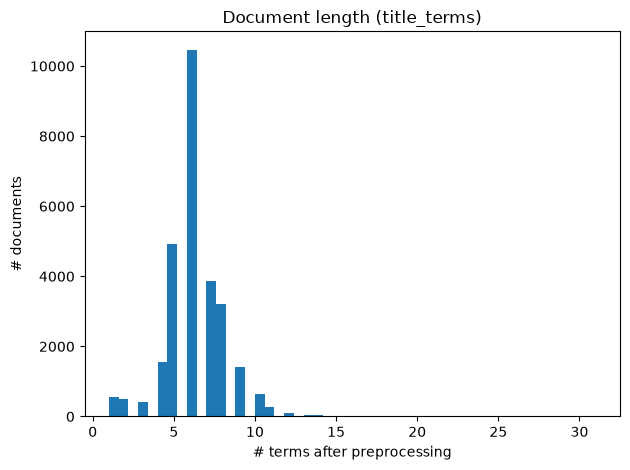

description_terms: vocab=4681, tokens=527535, mean len=18.8, median=9.0, max=567


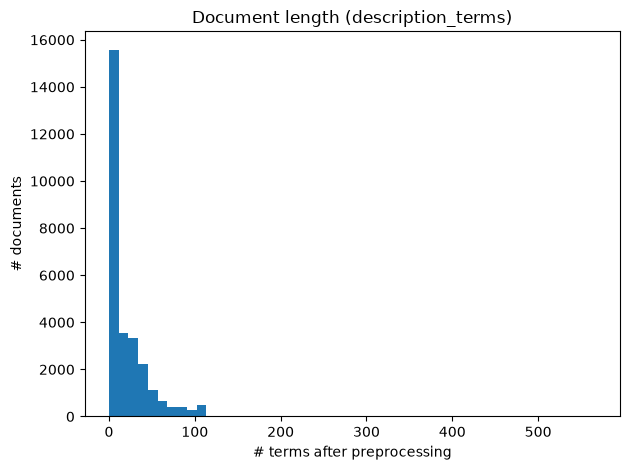

all_terms: vocab=6768, tokens=1885347, mean len=67.1, median=58.0, max=632


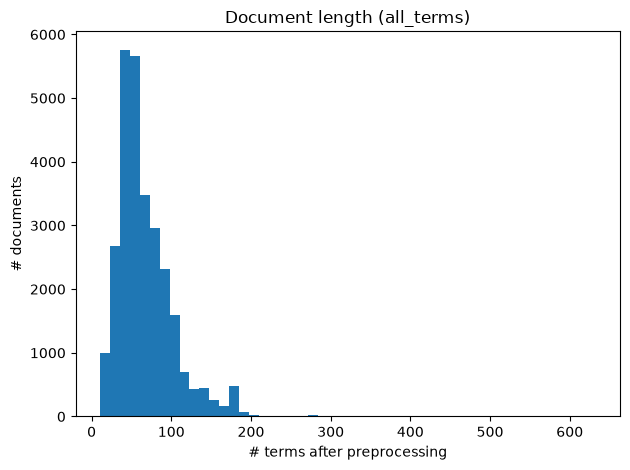

[('fabric', 57370), ('neck', 57363), ('sleev', 51332), ('shirt', 50038), ('fit', 39734), ('type', 38731), ('color', 37498), ('cotton', 34079), ('wear', 31691), ('cloth', 31084), ('accessori', 29204), ('round', 28500), ('men', 28248), ('women', 28041), ('regular', 27447), ('wash', 26831), ('pattern', 26595), ('print', 24064), ('care', 23746), ('solid', 22957), ('brand', 22537), ('suitabl', 19507), ('western', 19189), ('machin', 17958), ('ideal', 17770)]


In [13]:
for field in ["title_terms", "description_terms", "all_terms"]:
    lengths = df[field].apply(len)
    vocab = Counter(t for terms in df[field] for t in terms)
    print(f"{field}: vocab={len(vocab)}, tokens={sum(vocab.values())}, "
          f"mean len={lengths.mean():.1f}, median={lengths.median()}, max={lengths.max()}")
    plt.hist(lengths, bins=50); plt.title(f"Document length ({field})")
    plt.xlabel("# terms after preprocessing"); plt.ylabel("# documents")
    show(f"len_{field}")

vocab = Counter(t for terms in df["all_terms"] for t in terms)
print(vocab.most_common(25))

### 2.3 Word frequencies

Text(0, 0.5, 'frequency')

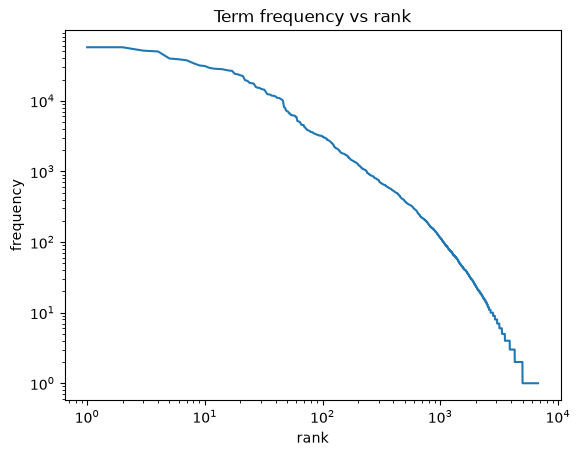

In [14]:
freqs = sorted(vocab.values(), reverse=True)
plt.loglog(range(1, len(freqs)+1), freqs)
plt.title("Term frequency vs rank"); plt.xlabel("rank"); plt.ylabel("frequency")

### 2.4 Average sentence length

In [15]:
desc = df["description"].dropna()
sample = desc.sample(min(5000, len(desc)), random_state=0)
lens = [len(s.split()) for d in sample for s in sent_tokenize(d)]
print("Average sentence length (words):", round(sum(lens)/len(lens), 2))
print("Average description length (words):", round(desc.str.split().str.len().mean(), 1))

Average sentence length (words): 15.85
Average description length (words): 29.8


### 2.5 Word clouds

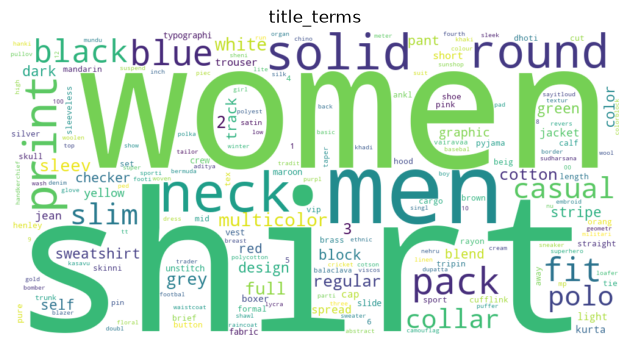

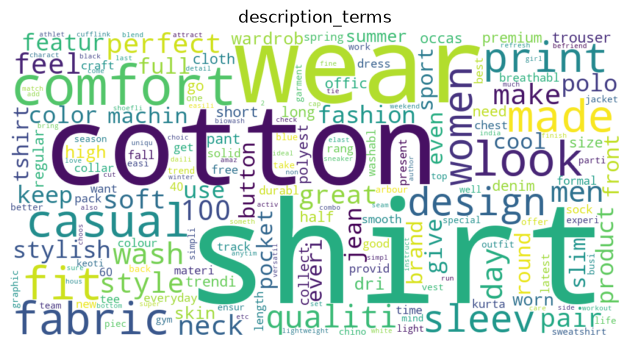

In [16]:
for field in ["title_terms", "description_terms"]:
    freq = Counter(t for terms in df[field] for t in terms)
    wc = WordCloud(width=1000, height=500, background_color="white").generate_from_frequencies(freq)
    plt.imshow(wc, interpolation="bilinear"); plt.axis("off"); plt.title(field)
    show(f"wordcloud_{field}")

### 2.6 Brands, sellers and categories

brand
                2009
ECKO Unl         951
Free Authori     860
ARBO             806
REEB             802
Pu               798
True Bl          793
Keo              660
Amp              585
Black Beat       548
vims rai         503
yellowvib        492
PixF             429
Oka              414
Gracew           405
Name: count, dtype: int64 
 brand unique values: 325 



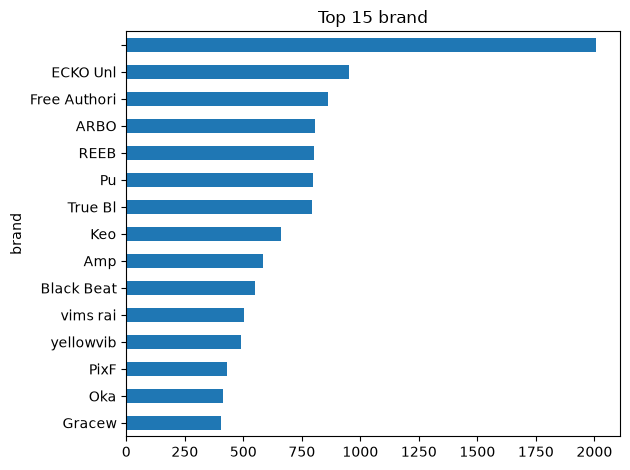

seller
                         1643
RetailNet                1411
SandSMarketing            887
BioworldMerchandising     842
ARBOR                     783
Keoti                     660
AFFGARMENTS               587
Black Beatle              548
AMALGUS ENTERPRISE        477
Tayab Manch Fashions      436
KAPSONSRETAILPVTLTD       415
GRACEWAY                  408
T-SHIRT EXPRESS           393
OKANE                     386
WHITE SKY                 371
Name: count, dtype: int64 
 seller unique values: 535 



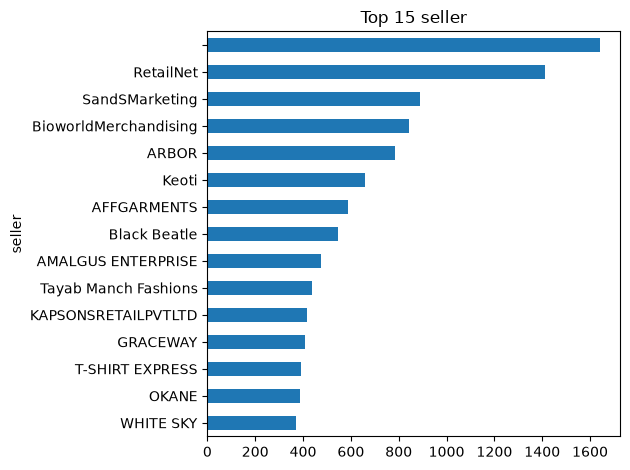

category
Clothing and Accessories    27118
Footwear                      920
Bags, Wallets & Belts          41
Toys                            1
Name: count, dtype: int64 
 category unique values: 4 



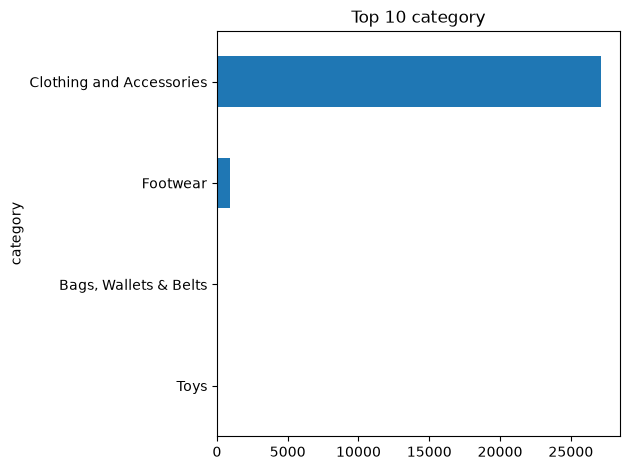

sub_category
Topwear                            15310
Bottomwear                          3666
Winter Wear                         2493
Innerwear and Swimwear              1762
Clothing Accessories                1742
Kurtas, Ethnic Sets and Bottoms     1180
Men's Footwear                       920
Fabrics                              534
Sleepwear                            122
Blazers, Waistcoats and Suits        103
Name: count, dtype: int64 
 sub_category unique values: 24 



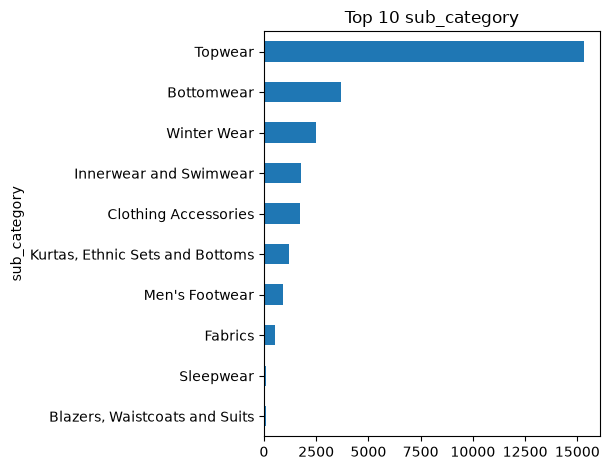

In [17]:
for col, n in [("brand", 15), ("seller", 15), ("category", 10), ("sub_category", 10)]:
    counts = df[col].value_counts().head(n)
    print(counts, "\n", col, "unique values:", df[col].nunique(), "\n")
    counts.iloc[::-1].plot(kind="barh"); plt.title(f"Top {n} {col}")
    show(f"top_{col}")

### 2.7 Out of stock

out_of_stock
False    94.15
True      5.85
Name: proportion, dtype: float64


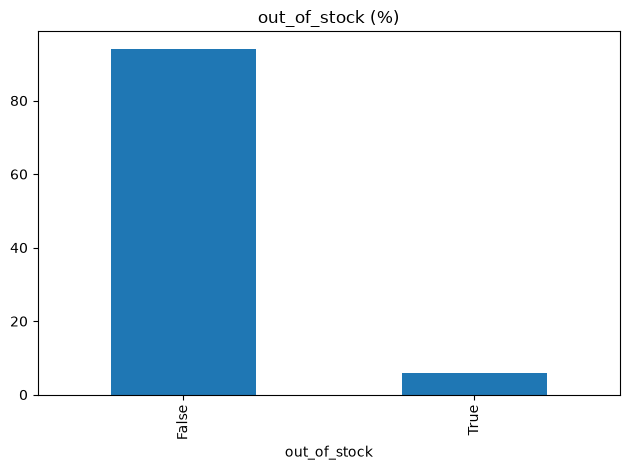

In [18]:
oos = df["out_of_stock"].value_counts(normalize=True) * 100
print(oos.round(2))
oos.plot(kind="bar"); plt.title("out_of_stock (%)")
show("out_of_stock")

### 2.8 Prices, discount and rating

selling_price 
 count    28078.00
mean       705.64
std        549.68
min         99.00
25%        390.00
50%        545.00
75%        820.00
max       7999.00
Name: selling_price, dtype: float64 



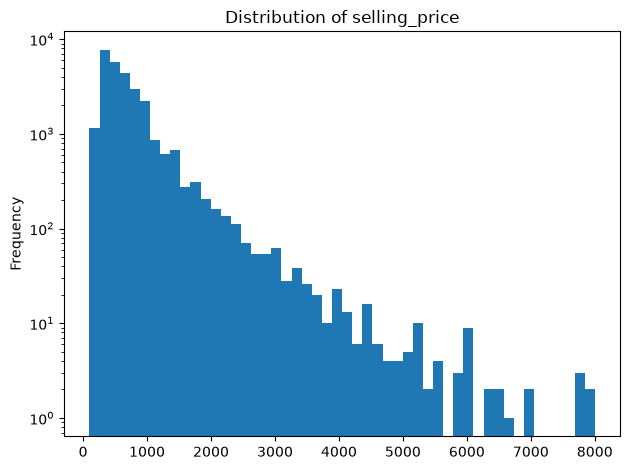

actual_price 
 count    27303.00
mean      1455.53
std        939.98
min        150.00
25%        849.00
50%       1199.00
75%       1799.00
max      12999.00
Name: actual_price, dtype: float64 



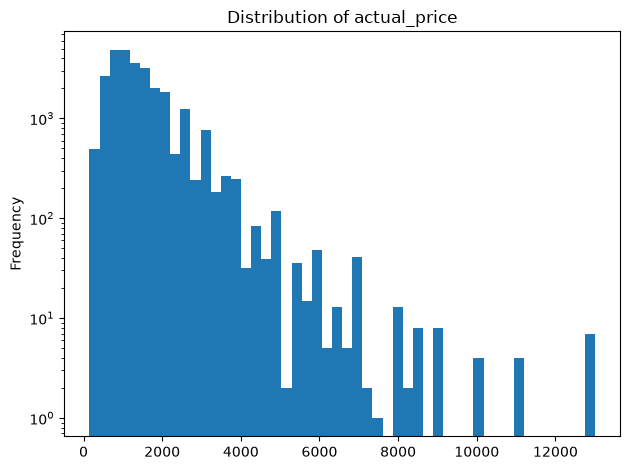

discount 
 count    27225.00
mean        50.26
std         16.89
min          1.00
25%         40.00
50%         53.00
75%         63.00
max         87.00
Name: discount, dtype: float64 



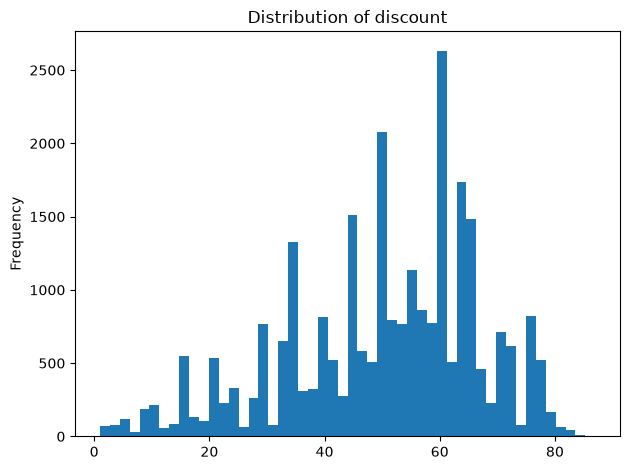

average_rating 
 count    25819.00
mean         3.63
std          0.66
min          1.00
25%          3.20
50%          3.80
75%          4.10
max          5.00
Name: average_rating, dtype: float64 



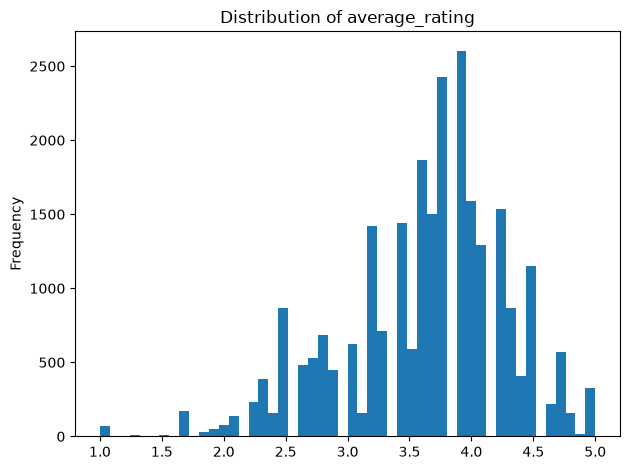

Top 10 by rating:


,pid,title,brand,selling_price,discount,average_rating
22361,BRFFM8J3XCQHKYYA,Men Brief (Pack of 5),COL,385.0,50.0,5.0
8403,VESFN9F35YWEEHDG,VIP Women Vest (Pack of 8),,1108.0,7.0,5.0
14764,TSHFUEUZDF7J7QDW,Graphic Print Women Round Neck White T-Shirt,TEE BUD,349.0,61.0,5.0
13240,BRFFFYHUQGBFXZTG,Men Brief (Pack of 5),VIKING.INE,699.0,NaN,5.0
10472,SHTFZZFERN6EPZNM,Men Slim Fit Printed Spread Collar Casual Shirt,True Bl,1119.0,60.0,5.0
12351,TSHFKH7VZA54W6UF,Printed Women Hooded Neck Black T-Shirt,ATTIITU,1499.0,NaN,5.0
13242,BRFFFEH4B6JVT5A5,Men Brief (Pack of 5),VIKING.INE,699.0,NaN,5.0
12349,TSHFGMGPBJXHH3XZ,Printed Men Hooded Neck Grey T-Shirt,ATTIITU,499.0,61.0,5.0
12348,TSHFCWYJYURDMMBU,"Solid Women Round Neck Black, Grey T-Shirt",ATTIITU,449.0,55.0,5.0
10470,TSHFQ4FWQ42YYX9F,Solid Women Polo Neck Red T-Shirt,True Bl,599.0,60.0,5.0


Top 10 most expensive:


,pid,title,brand,selling_price,discount,average_rating
2067,TKTFZ3YGGMMNBYEZ,Solid Women Track Suit,REEB,7999.0,20.0,2.7
11010,BZRFVAX2QGTEGHRH,Checkered Single Breasted Party Women Full Sle...,True Bl,7998.0,NaN,2.6
26089,SWSFUMFGQFKVZGYH,Full Sleeve Printed Men Sweatshirt,Pu,7799.0,40.0,4.5
25815,JCKFQF5KMJJ349H8,Full Sleeve Solid Women Casual Jacket,Pu,7799.0,40.0,3.7
6895,JEAF8S4GWU5YKQTF,Skinny Men Blue Jeans,G,7794.0,40.0,4.2
11008,BZRFVDGUJHTQHDAX,Self Design Single Breasted Party Women Full S...,True Bl,6998.0,NaN,2.6
6898,JEAF8S4GE8PKH7H3,Regular Fit Men Dark Blue Cotton Blend Trousers,G,6925.0,36.0,4.5
6901,JEAF65G3MZYG3BQM,Maxx Regular Men Black Jeans,G,6692.0,39.0,3.8
25423,JCKFQF5K72AT2JDC,Full Sleeve Solid Women Casual Jacket,Pu,6499.0,50.0,3.7
6855,JEAFEN3WGHH3ZEFY,Skinny Men Blue Jeans,G,6493.0,35.0,NaN


Top 10 by discount:


,pid,title,brand,selling_price,discount,average_rating
906,TSHF5FRXKGF6A4FH,Printed Women Round Neck White T-Shirt,Jack Roy,128.0,87.0,3.0
903,TSHFMFT7VASAHBH3,Printed Women Round Neck White T-Shirt,Jack Roy,136.0,86.0,4.7
902,TSHFMFXGFJ7G2ABK,Printed Women Round Neck Grey T-Shirt,Jack Roy,136.0,86.0,4.1
18249,TSHFGH6T3CVGDXS9,Printed Men Round Neck Multicolor T-Shirt (Pa...,yellowvib,449.0,85.0,3.2
9811,CAPE9YWMSVSZPM2K,Solid Balclava Cap,Gracew,228.0,84.0,4.3
18016,TSHFHQNCHJJUQYVQ,Printed Women Round Neck Blue T-Shirt,yellowvib,280.0,84.0,3.4
18017,TSHFKHRYJYMEMZHK,Printed Men Mandarin Collar Blue T-Shirt,yellowvib,282.0,84.0,4.2
18093,TSHFGFNBYVKZBQ2M,Printed Men Collared Neck Multicolor T-Shirt,yellowvib,230.0,84.0,4.6
91,CTPFVZTBN4GRZKXH,nu-Lite Satin Tie & Cufflink (Red),,499.0,84.0,2.7
3102,TSHFVM4PQPRY2CRZ,Color Block Women Round Neck Green T-Shirt,REF,228.0,84.0,4.2


In [ ]:
for col in ["selling_price", "actual_price", "discount", "average_rating"]:
    print(col, "\n", df[col].describe().round(2), "\n")
    df[col].dropna().plot(kind="hist", bins=50, logy=col.endswith("price"))
    plt.title(f"Distribution of {col}"); show(f"hist_{col}")

show_cols = ["pid", "title", "brand", "selling_price", "discount", "average_rating"]
print("Top 10 by rating:")
display(df.sort_values("average_rating", ascending=False)[show_cols].head(10))
print("Top 10 most expensive:")
display(df.sort_values("selling_price", ascending=False)[show_cols].head(10))
print("Top 10 by discount:")
display(df.sort_values("discount", ascending=False)[show_cols].head(10))

### 2.9 Named entity recognition

In [21]:
# one-time: python -m spacy download en_core_web_sm
import spacy
nlp = spacy.load("en_core_web_sm")
sample = df["description"].dropna().sample(2000, random_state=0)
ents = Counter()
for doc in nlp.pipe(sample, batch_size=64, disable=["parser", "lemmatizer"]):
    ents.update((e.label_, e.text) for e in doc.ents)

print(ents.most_common(25))
print(Counter(label for (label, _), c in ents.items() for _ in range(c)).most_common())

[(('PERCENT', '100%'), 215), (('PERCENT', '60%'), 85), (('PERCENT', '40%'), 80), (('GPE', 'Cotton'), 69), (('GPE', 'kurta'), 57), (('CARDINAL', 'half'), 44), (('DATE', 'daily'), 42), (('NORP', 'Jeans'), 40), (('DATE', 'weekend'), 39), (('DATE', 'Some days'), 36), (('DATE', 'all day'), 30), (('PERSON', 'Casual Wear'), 28), (('DATE', 'the day'), 28), (('GPE', 'Kurta'), 28), (('PERSON', 'Arbour'), 28), (('CARDINAL', '3'), 27), (('ORG', 'Printed'), 26), (('PERSON', 'Track Pant'), 26), (('PERSON', 'Cotton'), 25), (('CARDINAL', '2'), 20), (('DATE', 'winter'), 20), (('GPE', 'India'), 20), (('PERSON', 'Casual'), 20), (('PERSON', 'Denims'), 19), (('ORG', 'THE AMAZING COMFORT OF A Shoefly POLO T-SHIRTS'), 19)]
[('ORG', 1041), ('PERSON', 743), ('PERCENT', 401), ('DATE', 387), ('GPE', 335), ('CARDINAL', 251), ('NORP', 140), ('WORK_OF_ART', 138), ('TIME', 31), ('PRODUCT', 29), ('QUANTITY', 19), ('LAW', 13), ('FAC', 12), ('ORDINAL', 11), ('LOC', 7), ('EVENT', 7), ('MONEY', 4), ('LANGUAGE', 2)]
